# Филогенетический анализ представителей семейства Ursidae — Часть 2

В этой части проекта проводим байесовскую филогенетическую реконструкцию представителей семейства Ursidae с помощью MrBayes. Используем объединённое выравнивание генов CYTB и IRBP, подготовленное в первой части работы, с *Panthera pardus* в качестве внешней группы.

После построения дерева сравниваем результаты Bayesian Inference и Maximum Likelihood, а также проверяем сходимость MCMC и стабильность параметров модели в программе Tracer.

## 1. Байесовские методы

Для байесовского анализа в MrBayes загружаем объединённое выравнивание:

```text
execute combined.nex
set usebeagle=no
```

Выравнивание содержит 9 таксонов и 2414 нуклеотидных позиций.

### 1.1. Разделение данных на партиции и выбор внешней группы

Объединённое выравнивание разделяем на две партиции:

- **CYTB:** позиции 1–1140 (1140 п. н.).
- **IRBP:** позиции 1141–2414 (1274 п. н.).

```text
charset cytb = 1-1140
charset irbp = 1141-2414
partition by_gene = 2: cytb,irbp
set partition = by_gene
```

Внешняя группа (*outgroup*) — *Panthera pardus*:

```text
outgroup Panthera_pardus
showmodel
```

### 1.2. Настройка моделей нуклеотидных замен

Для обеих партиций используем модель HKY (`nst=2`) с гамма-распределением скоростей замен (`rates=gamma`). Для митохондриального гена CYTB дополнительно задаём генетический код митохондрий позвоночных (`code=vertmt`).

```text
lset applyto=(1) code=vertmt nst=2 rates=gamma
lset applyto=(2) nst=2 rates=gamma
showmodel
```

Для независимой оценки частот нуклеотидов (`statefreq`), параметра формы гамма-распределения (`shape`) и параметров матрицы замен (`revmat`) между партициями выполняем:

```text
unlink statefreq=(all) shape=(all) revmat=(all)
```

Для параметра формы гамма-распределения гена CYTB задаём экспоненциальное априорное распределение:

```text
prset applyto=(1) shapepr=exponential(10.0)
```

Таким образом, модели учитывают различия в частотах нуклеотидов, скоростях замен и неоднородности скоростей эволюции между генами CYTB и IRBP.

### 1.3. Настройка и запуск MCMC

Для оценки апостериорного распределения филогенетических деревьев выполняем MCMC-анализ в MrBayes со следующими параметрами:

```text
mcmcp ngen=1000000 nruns=2 nchains=2 samplefreq=200 burninfrac=0.2
mcmc filename=combined_1million
```

Анализ завершён после **1 000 000 поколений** без дополнительного продления MCMC. Результаты сохранены с префиксом `combined_1million`, включая файлы параметров моделей (`.p`) и выборок филогенетических деревьев (`.t`) для двух независимых запусков.

### 1.4. Анализ результатов MCMC и оценка сходимости

Для обобщения выборок параметров модели и филогенетических деревьев используем команды:

```text
sump filename=combined_1million
sumt filename=combined_1million
```

**Результаты анализа параметров (`sump`):**

В каждом из двух независимых запусков получено 5001 сохранённое значение параметров. После исключения первых 20% (*burn-in*) осталось по 4001 значению, всего **8002 выборки**.

- Минимальное значение **ESS** (Effective Sample Size) составило **820,54**, что указывает на достаточный эффективный размер выборки параметров.
- Значения **PSRF** (Potential Scale Reduction Factor) находились в диапазоне **1,000–1,001**, что свидетельствует о хорошем согласовании оценок параметров между независимыми запусками.

**Результаты анализа деревьев (`sumt`):**

Из 10 002 сохранённых деревьев после исключения *burn-in* использовано **8002 дерева**.

- Среднее стандартное отклонение частот расщеплений (**ASDSF**) составило **0,019918**.
- Максимальное стандартное отклонение частот расщеплений составило **0,038174**.
- Среднее значение PSRF для длин ветвей составило **1,001**, максимальное — **1,012**.

Значение ASDSF превышает рекомендуемый порог **0,01**. Следовательно, несмотря на хорошие показатели ESS и PSRF для параметров модели, **полная сходимость топологий филогенетических деревьев между независимыми запусками не подтверждена**.

На основании выборки деревьев MrBayes построил консенсусное филогенетическое дерево, сохранённое в файле `combined_1million.con.tre`.

Таким образом, результаты анализа параметров указывают на хорошее смешивание цепей MCMC (*good mixing*).

### 1.5. Визуализация и интерпретация байесовского дерева

Консенсусное дерево MrBayes (combined_1million.con.tre) визуализировано в FigTree. Поддержка внутренних узлов представлена апостериорными вероятностями (posterior probabilities, PP).

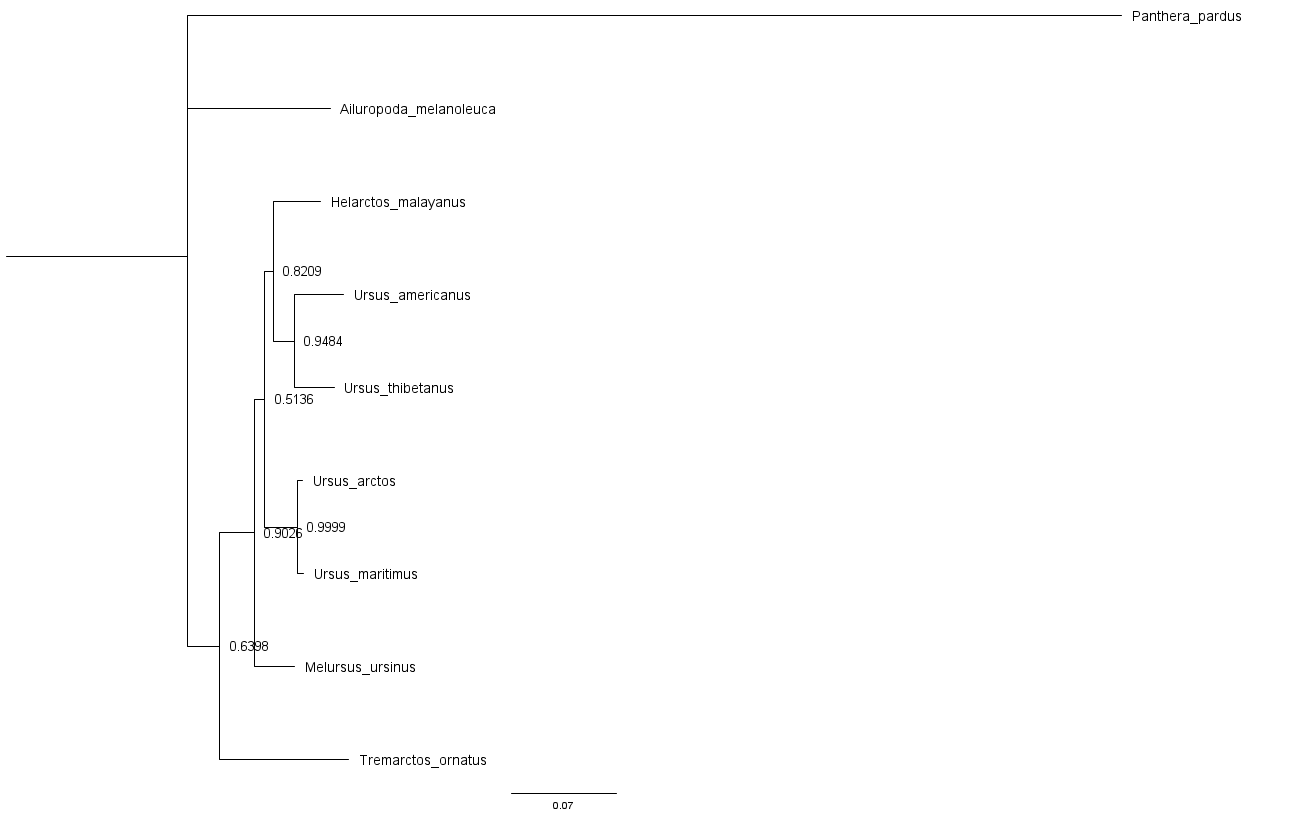

**Основные результаты:**

Ursus arctos и Ursus maritimus образуют кладу с очень высокой поддержкой (PP = 0,9999).

Ursus americanus и Ursus thibetanus объединяются в кладу с высокой поддержкой (PP = 0,9484).

Helarctos malayanus группируется с кладой U. americanus и U. thibetanus (PP = 0,8209).

Некоторые более глубокие узлы имеют сравнительно низкую поддержку (PP = 0,5136 и 0,6398).

Внешняя группа — Panthera pardus. Ailuropoda melanoleuca располагается отдельно от остальных исследованных представителей Ursidae.

Таким образом, байесовский анализ уверенно поддерживает близкое родство U. arctos и U. maritimus, тогда как положение некоторых глубоких ветвей остаётся менее определённым. При интерпретации дерева также учитываем ASDSF = 0,019918, указывающее на недостаточно подтверждённую сходимость топологий между независимыми запусками MCMC.

### 1.6. Сравнение филогенетических деревьев ML и BI

Для сравнения с байесовской реконструкцией используем филогенетическое дерево, построенное методом максимального правдоподобия (Maximum Likelihood, ML) в программе IQ-TREE с разделением данных на две партиции — CYTB и IRBP.

**Филогенетическое дерево ML:**

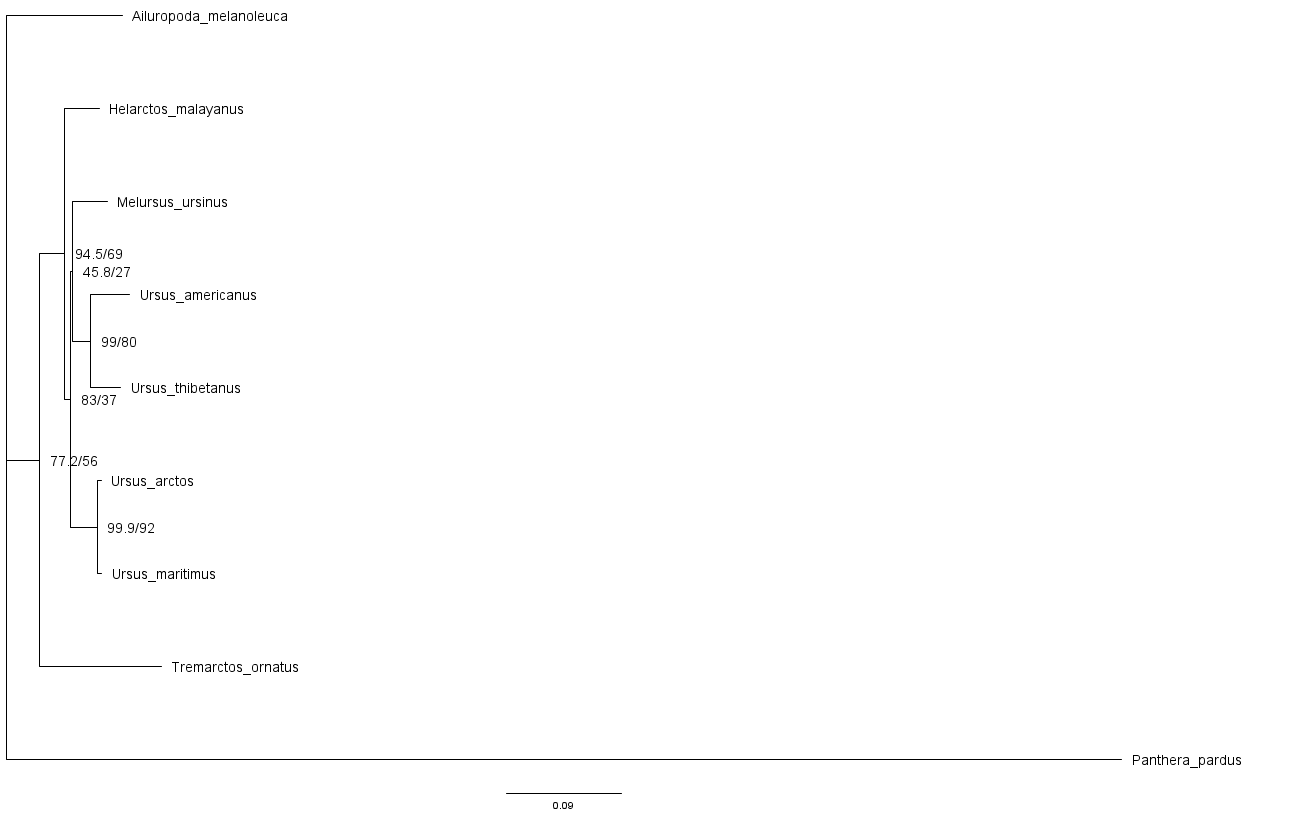

**Рисунок.** Филогенетическое дерево представителей семейства Ursidae, построенное методом максимального правдоподобия (IQ-TREE). Значения у внутренних узлов обозначают поддержку SH-aLRT / UFBoot.


#### Сравнение топологии

Оба метода выявили одинаковые близкородственные группы:

- *Ursus arctos* и *Ursus maritimus* образуют общую кладу.
- *Ursus americanus* и *Ursus thibetanus* также объединяются в одну кладу.
- *Panthera pardus* используется как внешняя группа, а *Ailuropoda melanoleuca* отделяется от остальных исследованных медведей.

Основные различия связаны с положением *Helarctos malayanus* и *Melursus ursinus*. В байесовском дереве *H. malayanus* группируется с *U. americanus* и *U. thibetanus* (**PP = 0,8209**), тогда как в дереве ML эта клада не воспроизводится. Следовательно, топологии деревьев частично совпадают, но не идентичны.

#### Сравнение статистической поддержки

| Клада | ML (SH-aLRT / UFBoot) | BI (PP) |
|---|---|---|
| *U. arctos* + *U. maritimus* | 99,9 / 92 | 0,9999 |
| *U. americanus* + *U. thibetanus* | 99 / 80 | 0,9484 |

Оба метода хорошо поддерживают эти клады. Однако некоторые глубокие узлы имеют низкую поддержку: в ML — **SH-aLRT / UFBoot = 45,8 / 27**, в BI — **PP = 0,5136**.

Показатели SH-aLRT и UFBoot характеризуют статистическую поддержку ветвей в ML, тогда как PP представляет апостериорную вероятность клады при заданной модели.

#### Какой метод предпочтительнее?

В данном исследовании оба метода согласуются в определении основных близкородственных групп. Для интерпретации более глубоких связей я бы предварительно предпочёл **ML**, поскольку в байесовском анализе **ASDSF = 0,019918** превышает рекомендуемый порог **0,01**, и сходимость топологий между независимыми запусками не подтверждена полностью.

Это не означает, что ML всегда надёжнее BI: оба метода зависят от качества выравнивания, выбранных моделей и диагностики анализа. После достижения удовлетворительной сходимости MCMC байесовский метод также может давать надёжные оценки филогенетических отношений.

**Вывод:** ML и BI согласуются в определении основных близкородственных групп, но различаются в расположении некоторых внутренних ветвей. Наиболее обоснованными являются связи, получающие высокую поддержку обоими методами.


## Б. Диагностика модели и калибровка филогенетических деревьев

### 1. Диагностика MCMC в Tracer
В программу Tracer загружены файлы `combined_1million.run1.p` и `combined_1million.run2.p`. Для каждого запуска исключены первые 20% выборок (burn-in).

Распределения маргинальных вероятностей и Trace-графики показывают хорошее смешивание цепей. Значения ESS для исследованных параметров превышают 200. Средние значения LnL близки: −6957,32 и −6957,34.

**Ответы на вопросы:**

1. **Была ли достигнута точка оптимума?** Цепи вышли на стабильную область параметров, однако достижение глобального оптимума не доказано.
2. **Есть ли различия между цепями?** Существенных различий в исследованных распределениях не обнаружено.
3. **Какие параметры нестабильны?** Явной нестабильности исследованных параметров не выявлено. Значения α различаются между генами: CYTB ≈ 0,176, IRBP ≈ 0,045.
4. **Вывод о дереве MrBayes:** Байесовское дерево уверенно поддерживает основные близкородственные группы, особенно *Ursus arctos* и *Ursus maritimus*. Однако положение некоторых внутренних ветвей остаётся менее определённым из-за более низких значений апостериорных вероятностей.

#### Сравнение маргинальных распределений LnL

Для двух независимых запусков MCMC сравнили маргинальные распределения логарифма правдоподобия (LnL).

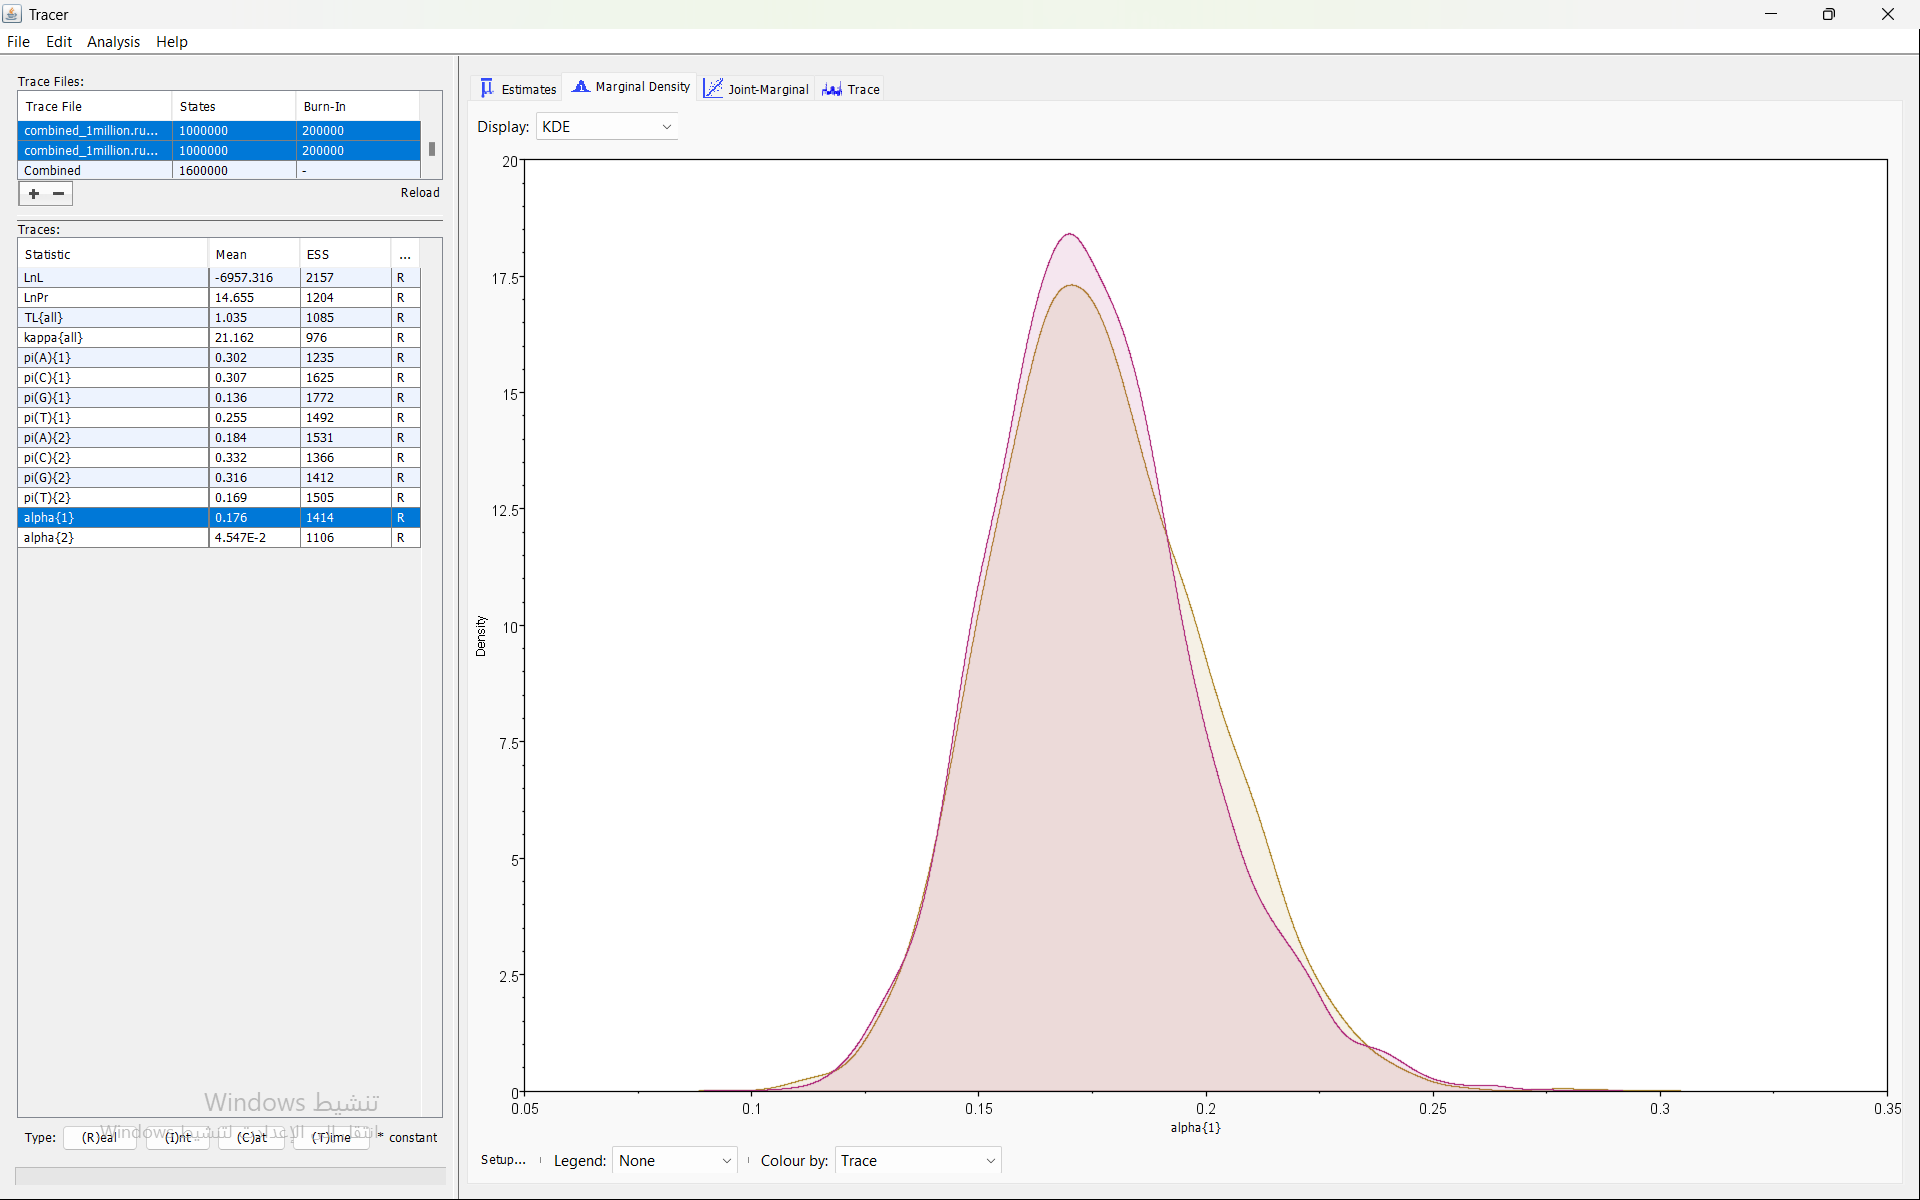

**Рисунок.** Маргинальные распределения LnL для Run 1 и Run 2 после исключения 20% burn-in.

Распределения значительно перекрываются, а средние значения близки (−6957,32 и −6957,34), что указывает на хорошее согласование двух запусков по LnL.

#### Анализ Trace-графика LnL

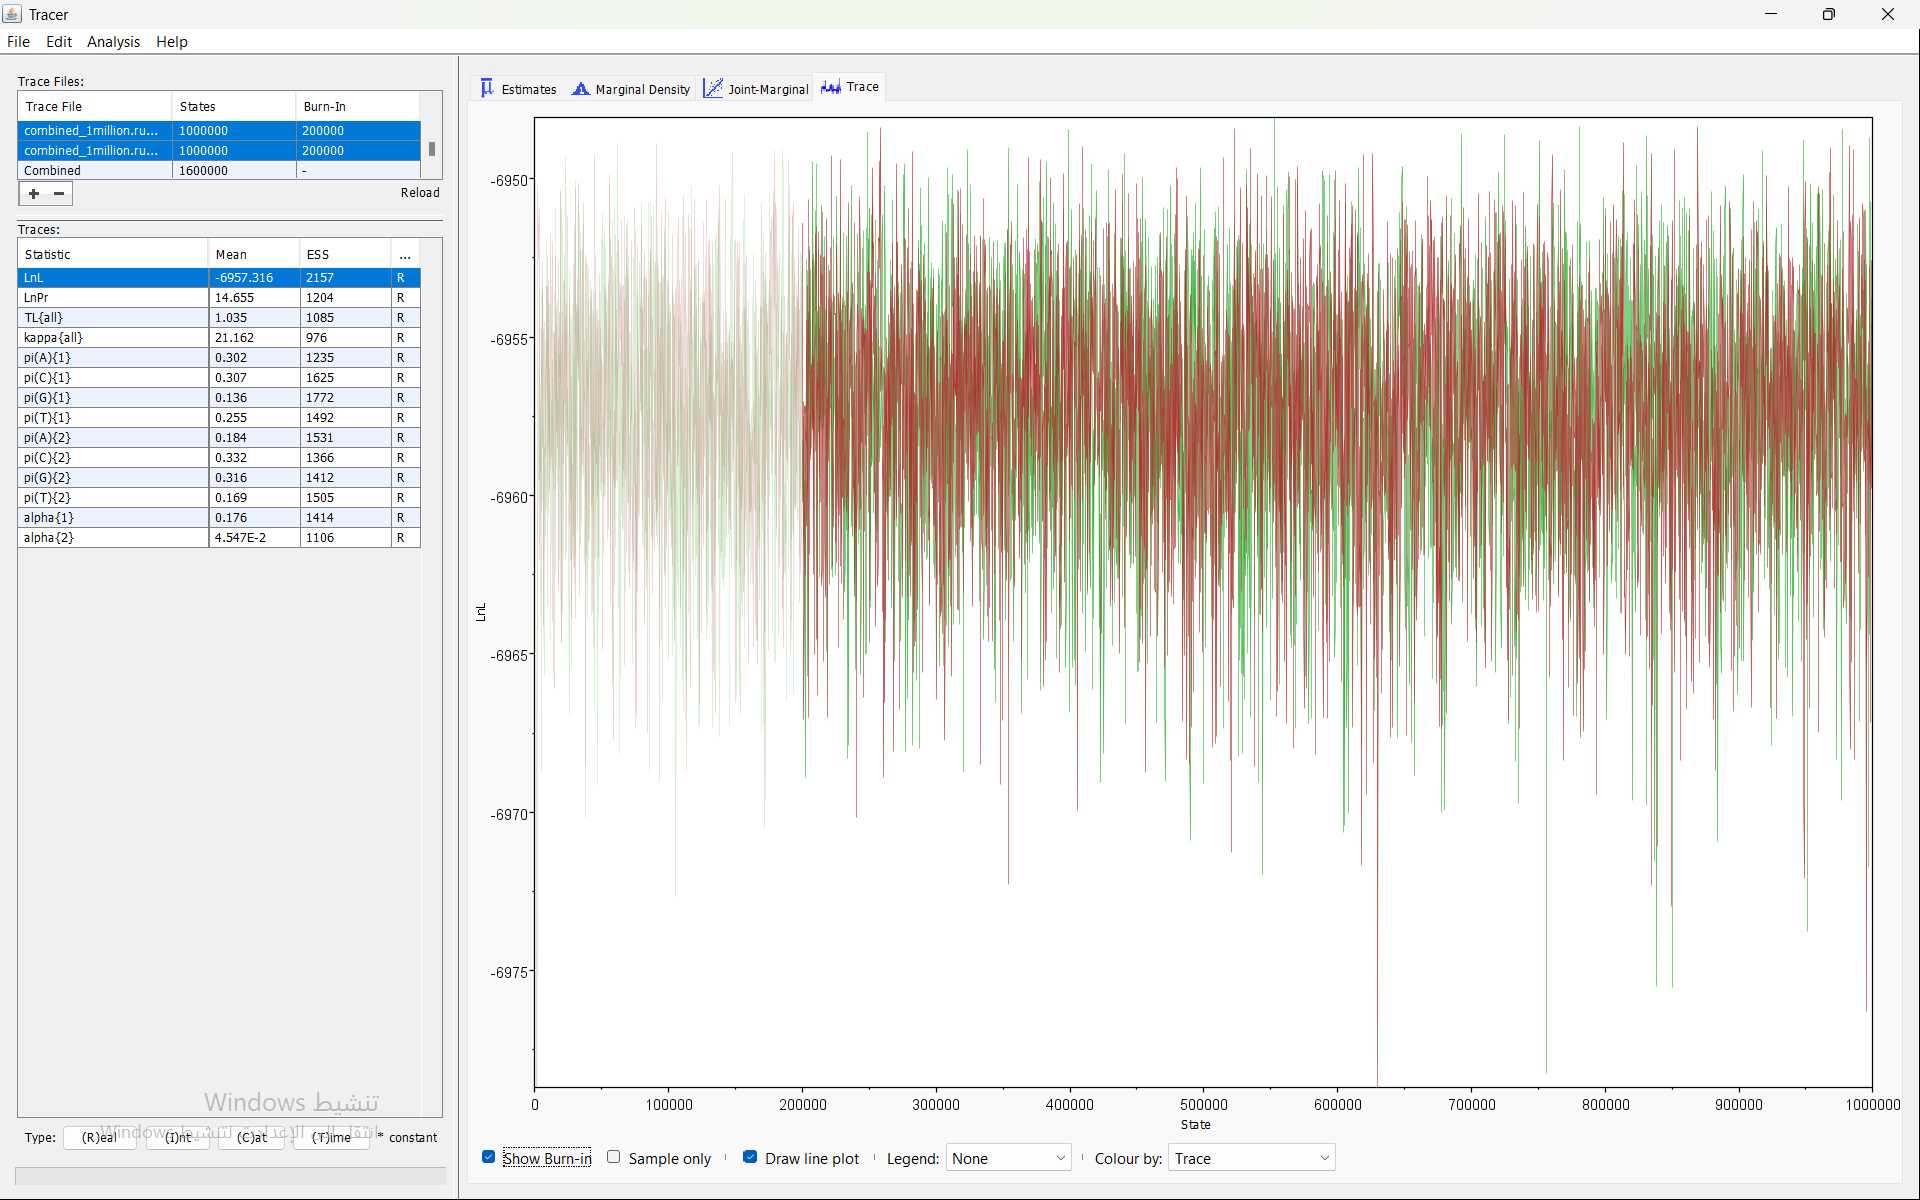

**Рисунок.** Trace-график LnL для двух независимых запусков MCMC в Tracer.

После исключения первых 20% поколений (burn-in) значения LnL колеблются вокруг стабильного уровня без выраженного направленного тренда. Траектории двух запусков перекрываются, что свидетельствует о хорошем смешивании цепей по LnL.

#### Анализ параметра kappa

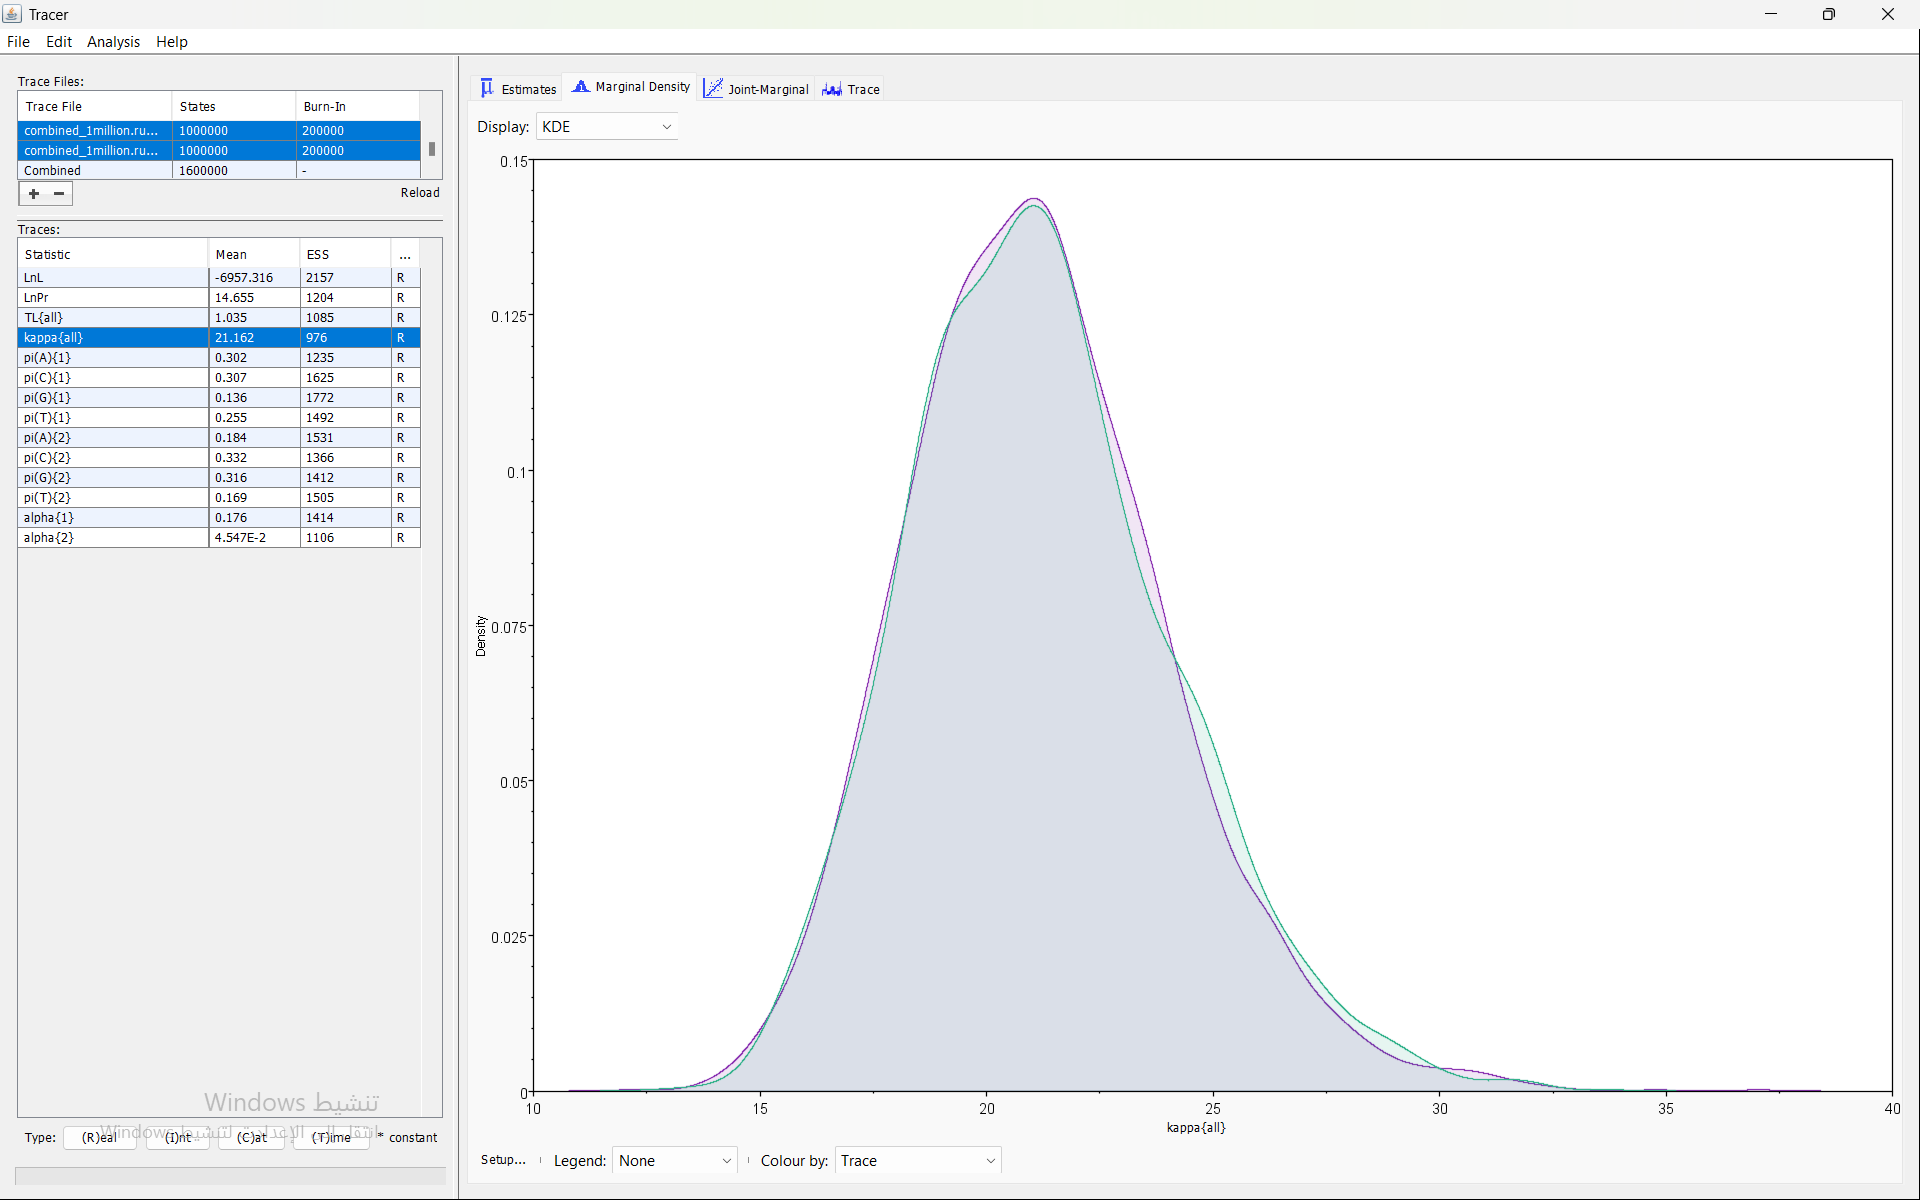

**Рисунок.** Сравнение маргинальных распределений параметра kappa для двух независимых запусков MCMC.

Распределения параметра kappa в двух запусках практически совпадают. Среднее значение составляет около 21. Значения ESS превышают 200, что свидетельствует о достаточно эффективном отборе выборок и согласованности оценок этого параметра.

#### Анализ параметра alpha для гена CYTB

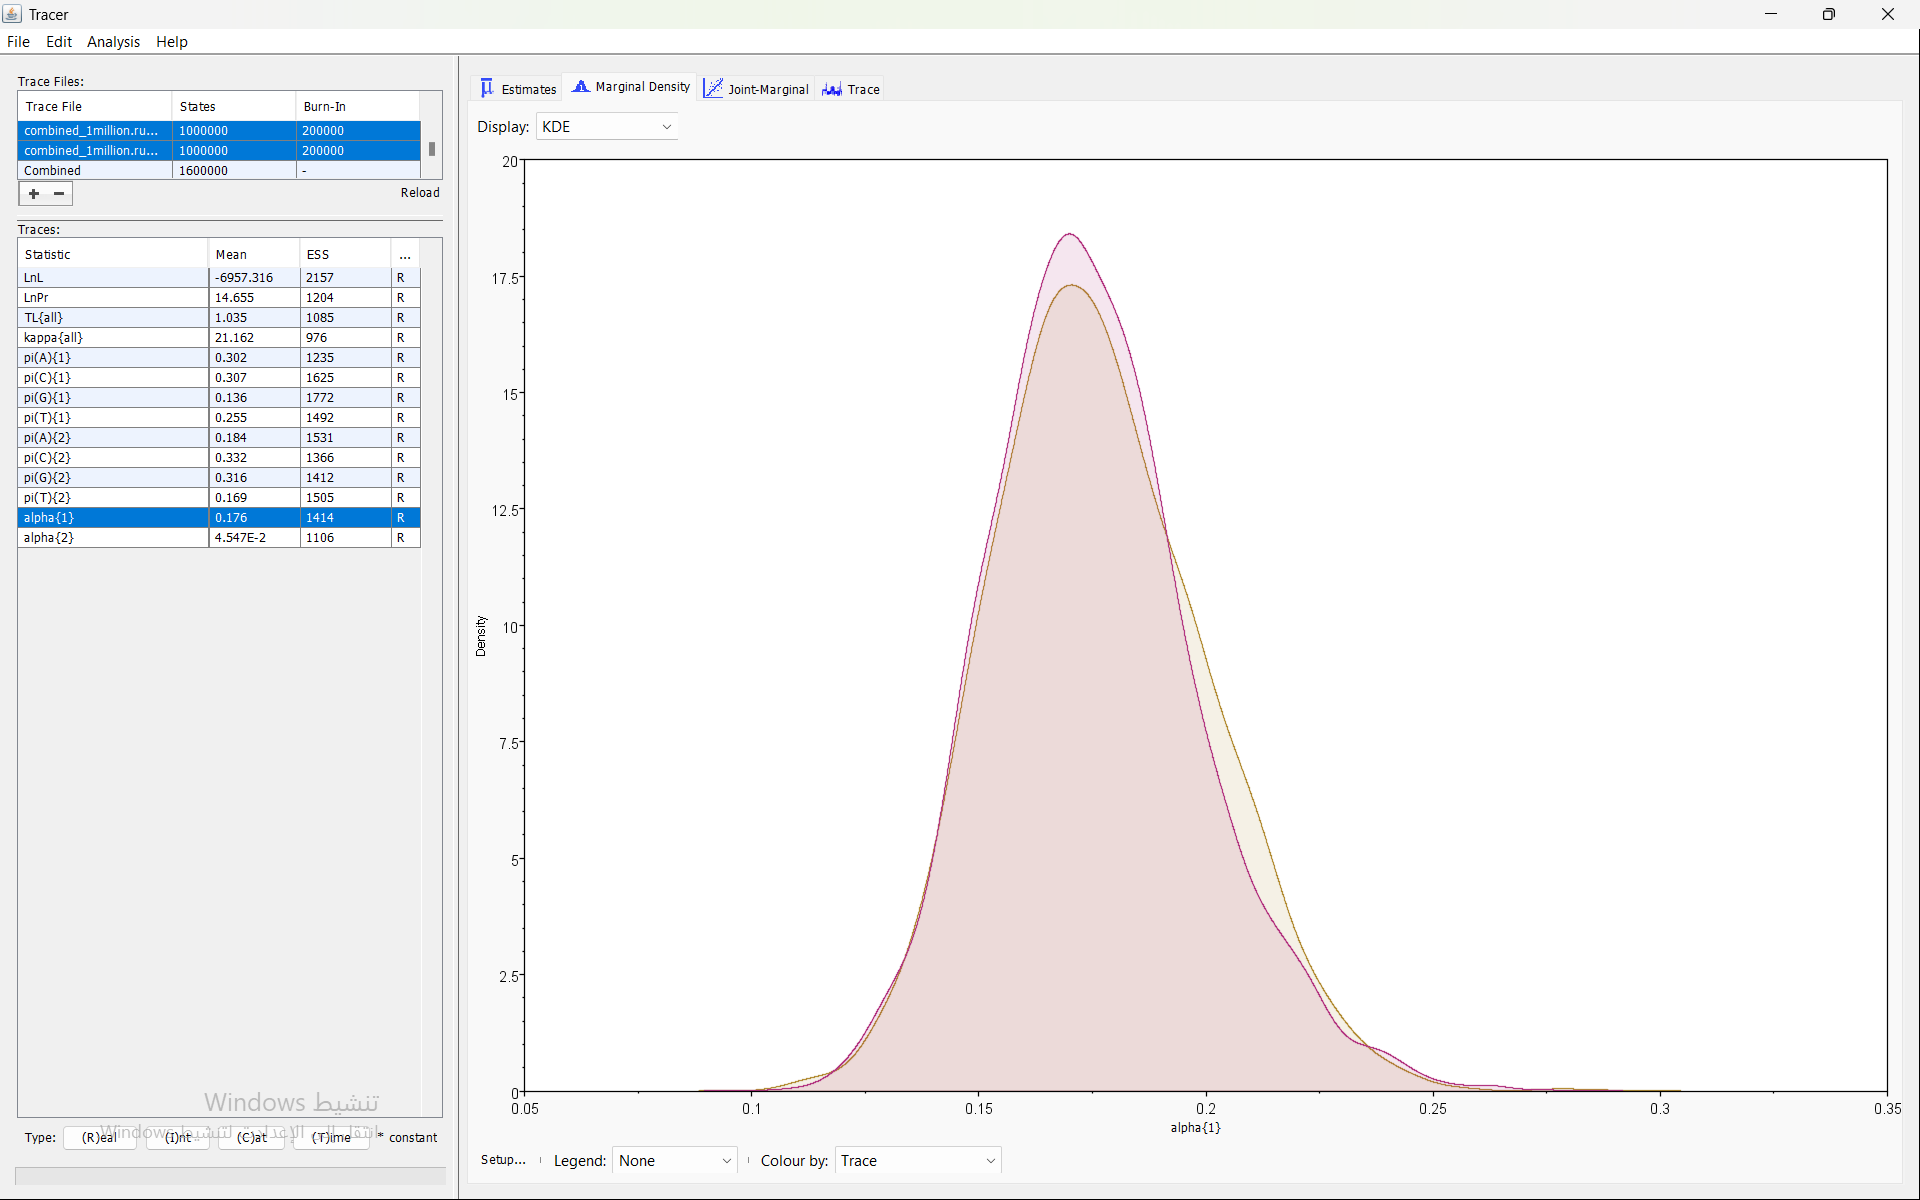

**Рисунок.** Маргинальные распределения параметра alpha для гена CYTB в двух независимых запусках MCMC.

Распределения практически совпадают, среднее значение alpha составляет около 0,176. Значения ESS превышают 200, что указывает на хорошую согласованность оценок параметра между запусками.

#### Анализ параметра alpha для гена IRBP

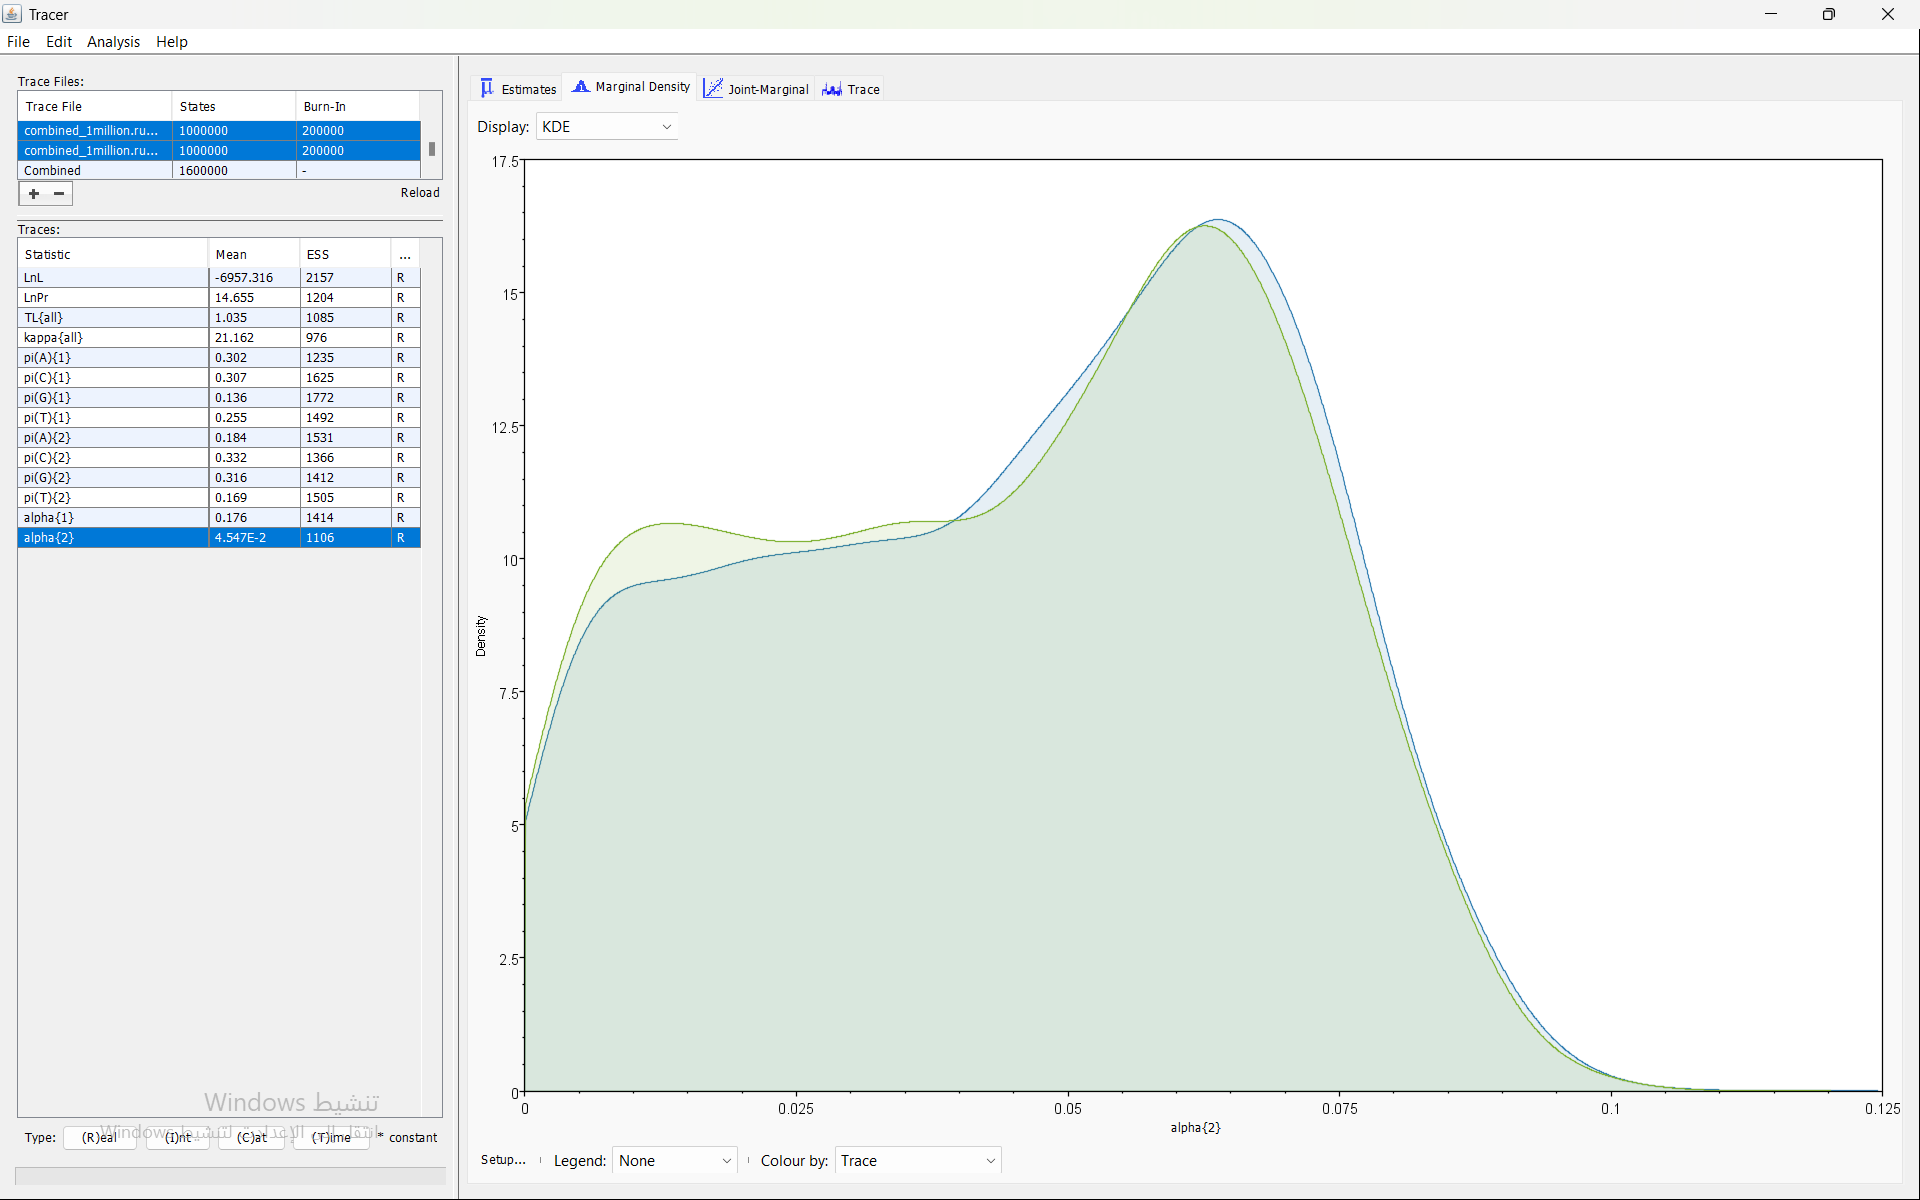

**Рисунок.** Маргинальные распределения параметра alpha для гена IRBP в двух независимых запусках MCMC.

Распределения двух запусков хорошо перекрываются. Среднее значение alpha составляет около 0,045, а значения ESS превышают 200.

#### Сравнение параметра alpha между генами CYTB и IRBP

Для гена CYTB среднее значение alpha составляет около 0,176, а для IRBP — около 0,045.

Таким образом, параметр alpha для IRBP заметно ниже, чем для CYTB. В гамма-модели это указывает на более выраженную неоднородность скоростей замен между сайтами гена IRBP.

При этом распределения alpha между двумя запусками MCMC согласуются для каждого гена, поэтому различие между CYTB и IRBP не следует считать признаком нестабильности цепей.

### Trace-график логарифма апостериорной вероятности

Для двух независимых запусков MrBayes рассчитан показатель
LnPosterior = LnL + LnPr. Полученные данные проанализированы
в Tracer после исключения первых 20% выборок (burn-in).

После burn-in траектории обоих запусков перекрываются и
колеблются вокруг близких значений без выраженного тренда.
Средние значения LnPosterior составляют −6942,661 и −6942,689,
а ESS — 2378 и 2071 соответственно.

Таким образом, Trace-график указывает на стабильность
логарифма апостериорной вероятности и хорошее смешивание
цепей в обоих запусках.

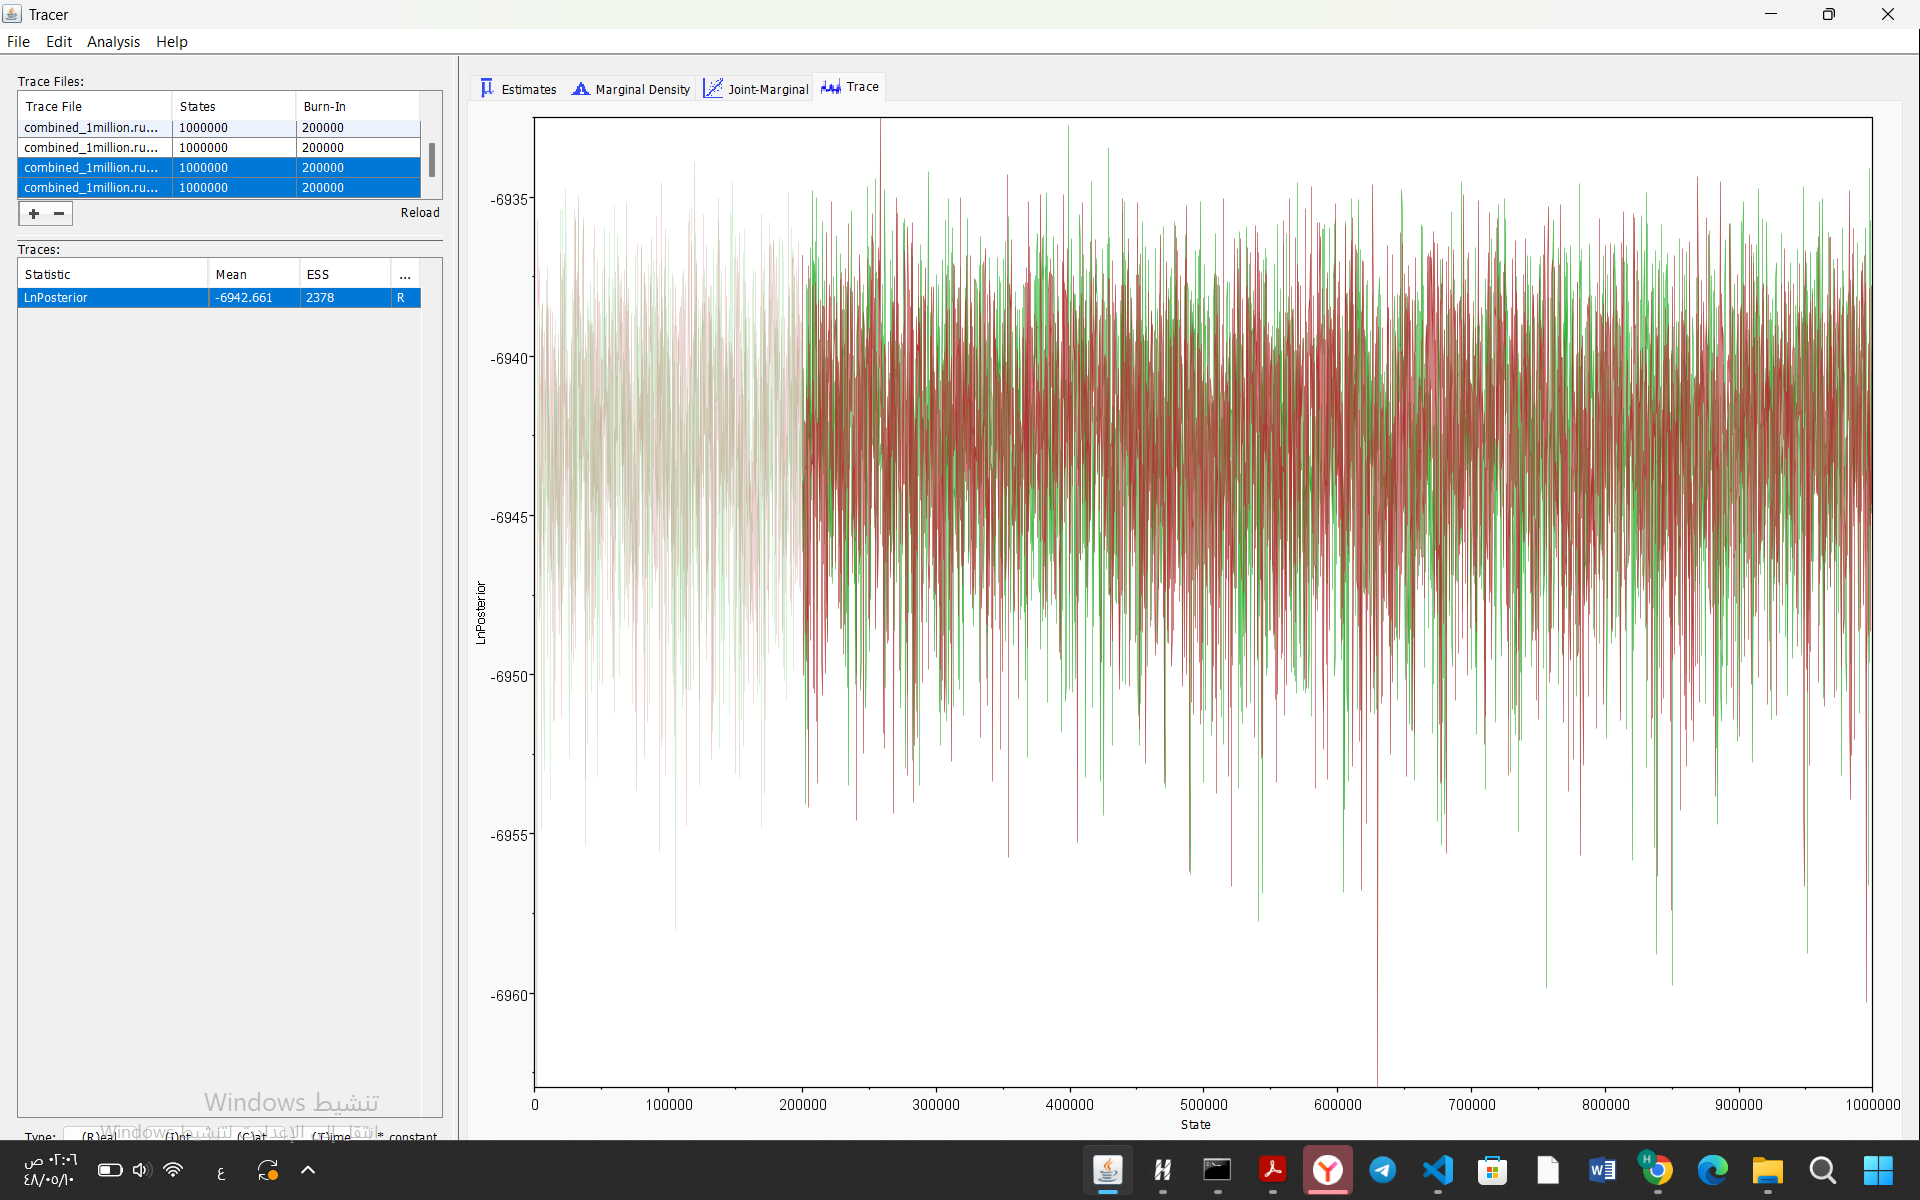


## Дополнительное задание: калибровка филогенетического дерева в BEAST2

Для оценки времени дивергенции медвежьих (Ursidae) был проведён байесовский анализ в программе **BEAST2** по двум генам — **cytb** и **irbp**, без внешней группы.

Для каждого гена использовалась модель замен **HKY + G** с четырьмя категориями скоростей. Для обоих генов были заданы общее дерево и молекулярные часы **Optimised Relaxed Clock (ORC)**. В качестве априорной модели дерева использовалась **Birth–Death**.

Калибровка проводилась для монофилетической клады *Ursus arctos* и *Ursus maritimus* с логнормальным распределением возраста общего предка (Offset = 11,2; Mean = 0,3; SD = 0,8).

Длина MCMC составила **1 000 000 поколений**, предварительный прогрев — **100 000 поколений**. В TreeAnnotator после удаления 20 % деревьев было построено дерево максимальной достоверности клад (**MCC**) со средними высотами узлов.

Оценённый возраст общего предка *U. arctos* и *U. maritimus* составил **11,47 млн лет**, а возраст корня дерева — **15,59 млн лет**. Первая оценка зависит от заданной калибровки.

В Tracer для многих параметров значения ESS оказались ниже 200.

### Калиброванное филогенетическое дерево BEAST2

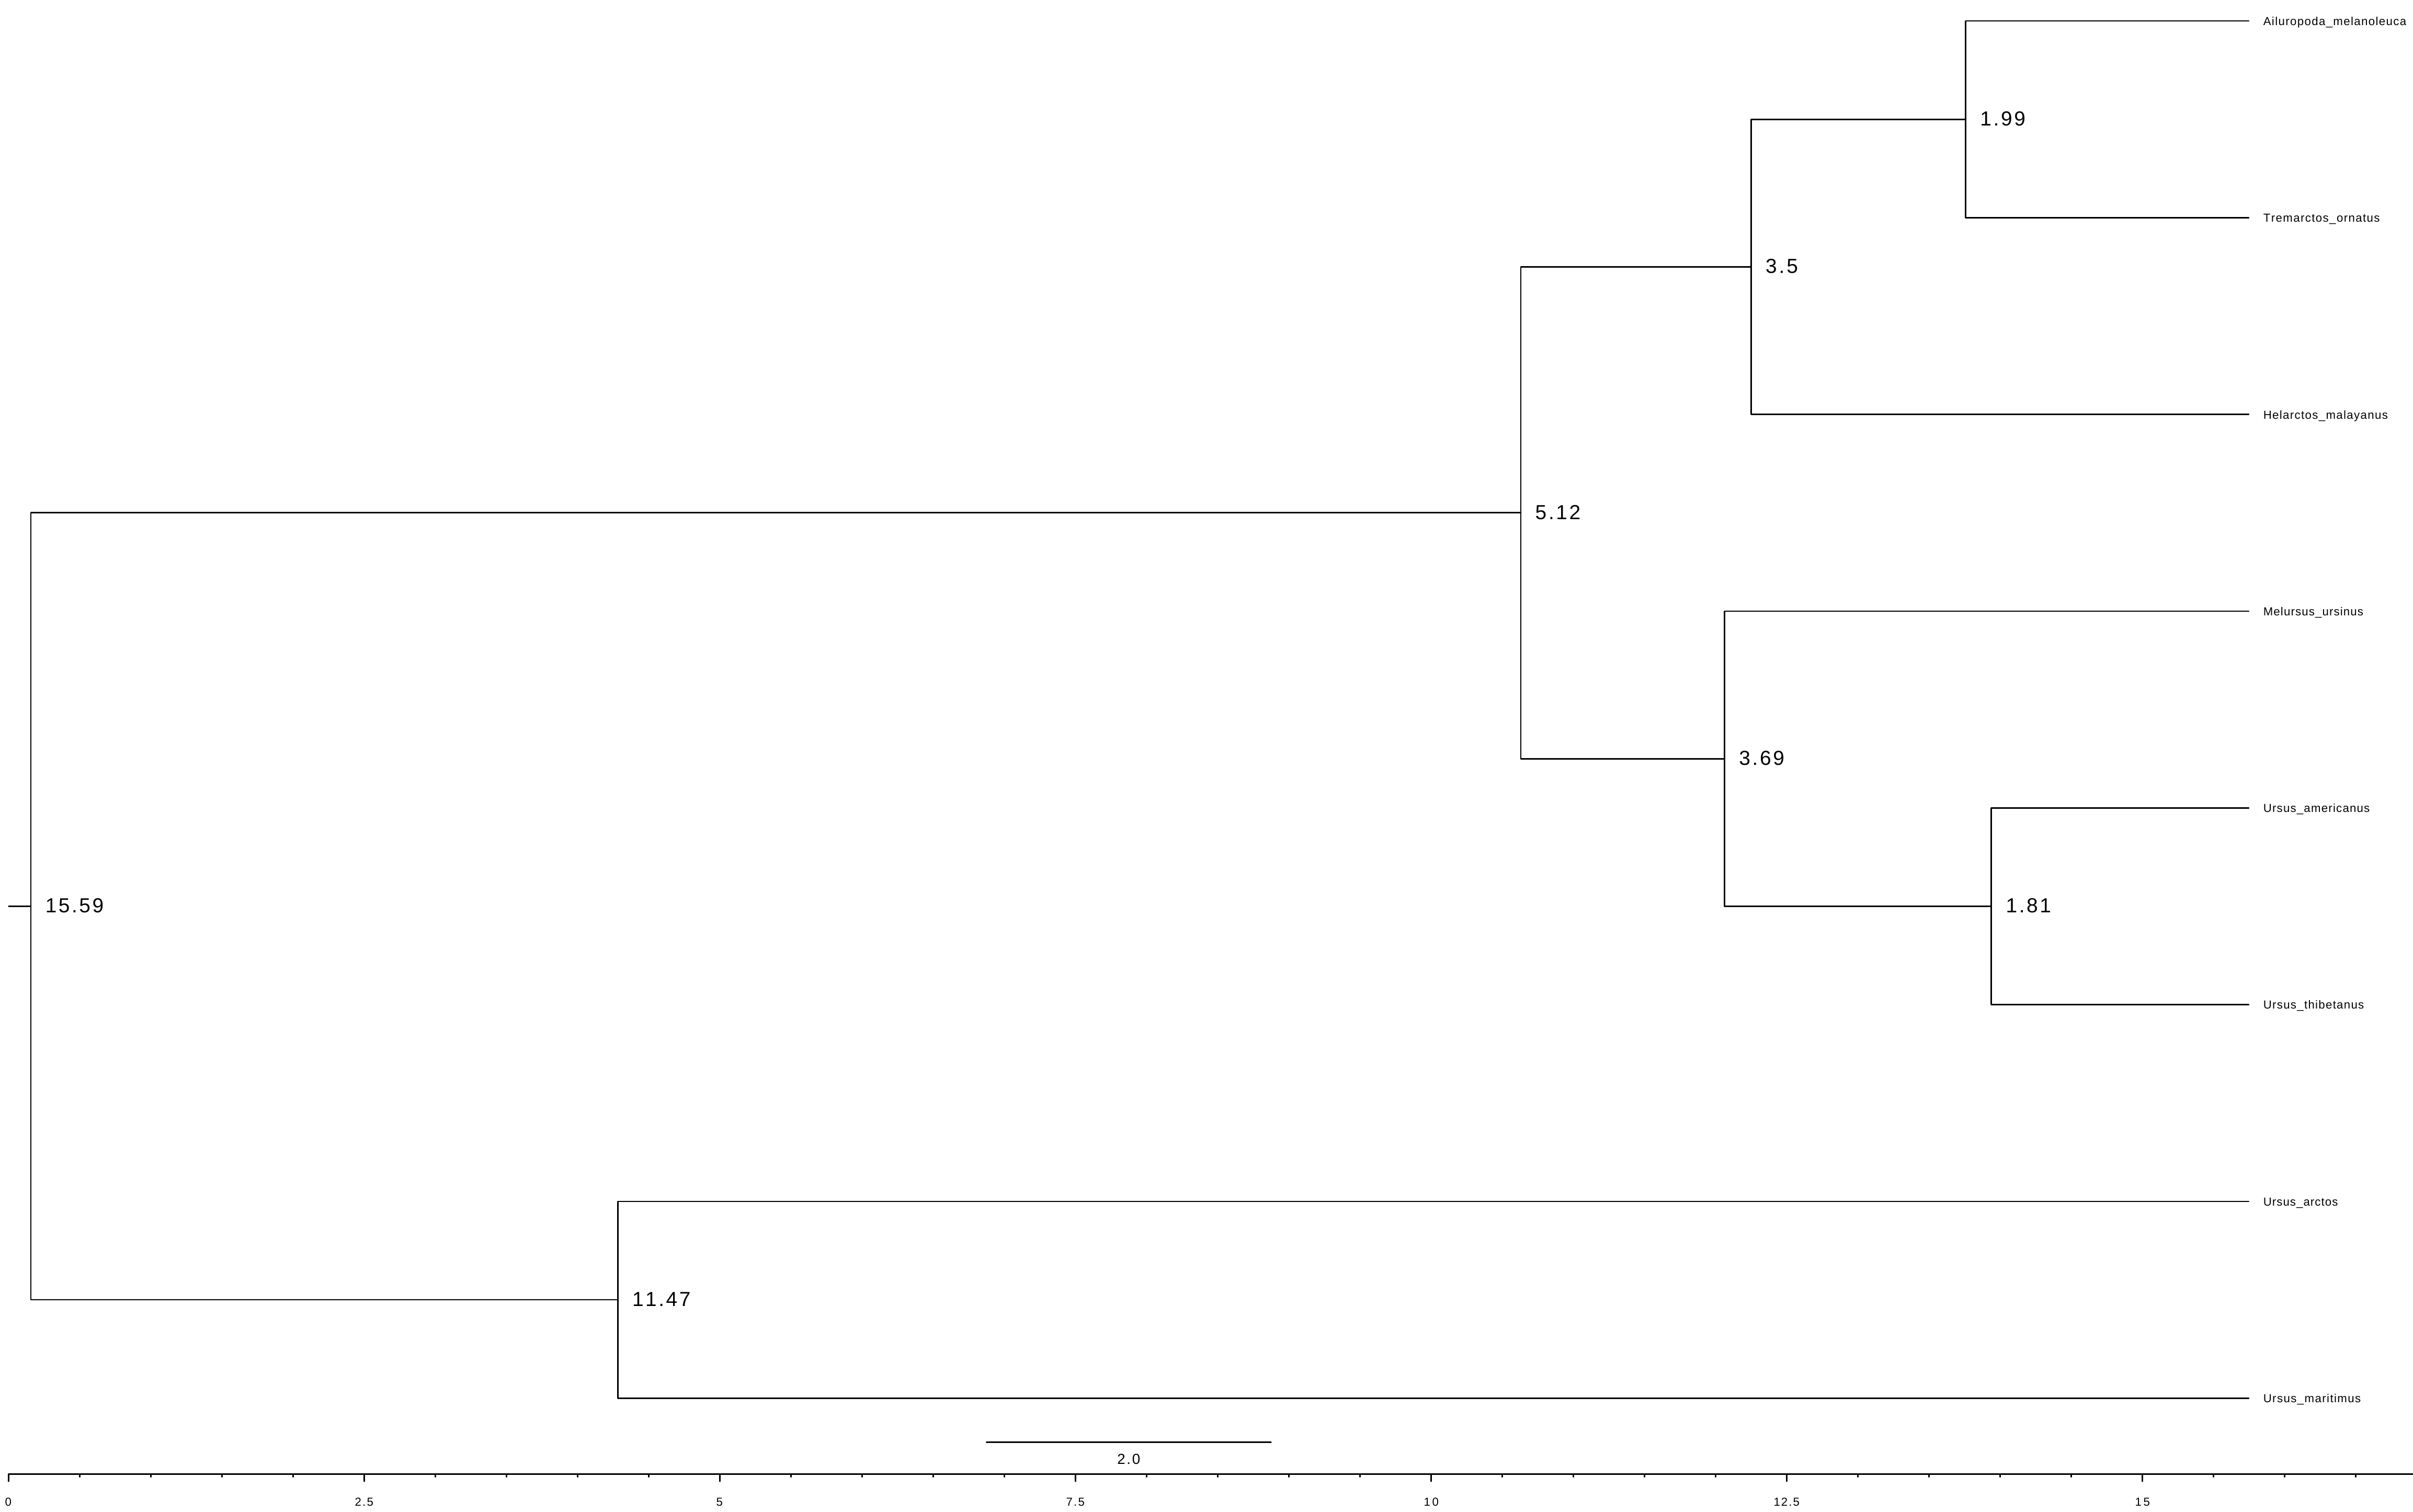

*Рисунок. Филогенетическое дерево семейства Ursidae, построенное в BEAST2 с временной калибровкой. Длины ветвей соответствуют времени в миллионах лет.*

### Диагностика MCMC в программе Tracer

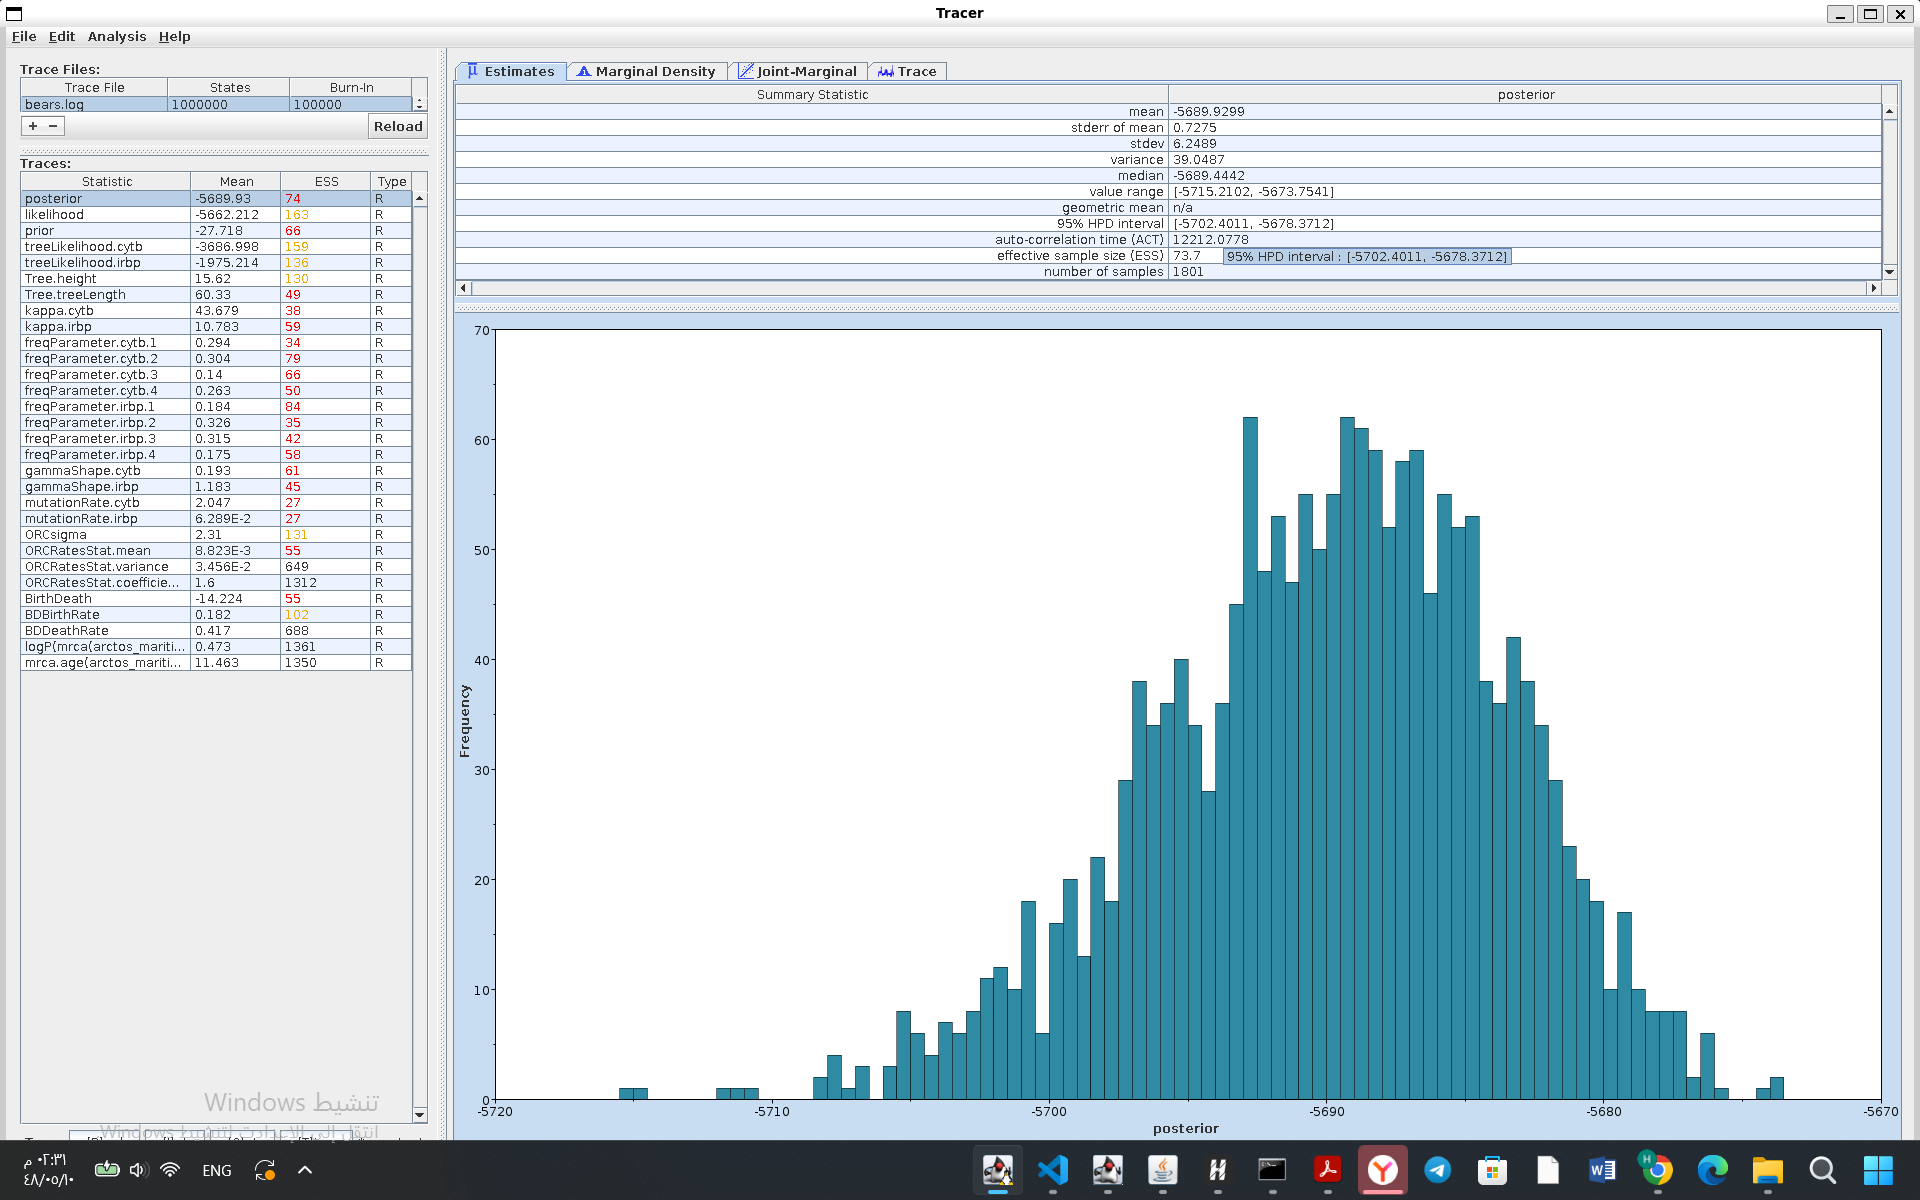

*Рисунок. Анализ результатов MCMC в программе Tracer. Для ряда параметров эффективный размер выборки (ESS) оказался ниже рекомендуемого порога 200, что указывает на недостаточную эффективность выборки. Поэтому оценки времени дивергенции следует интерпретировать с осторожностью.*

### Сравнение длин ветвей: метод максимального правдоподобия (ML)

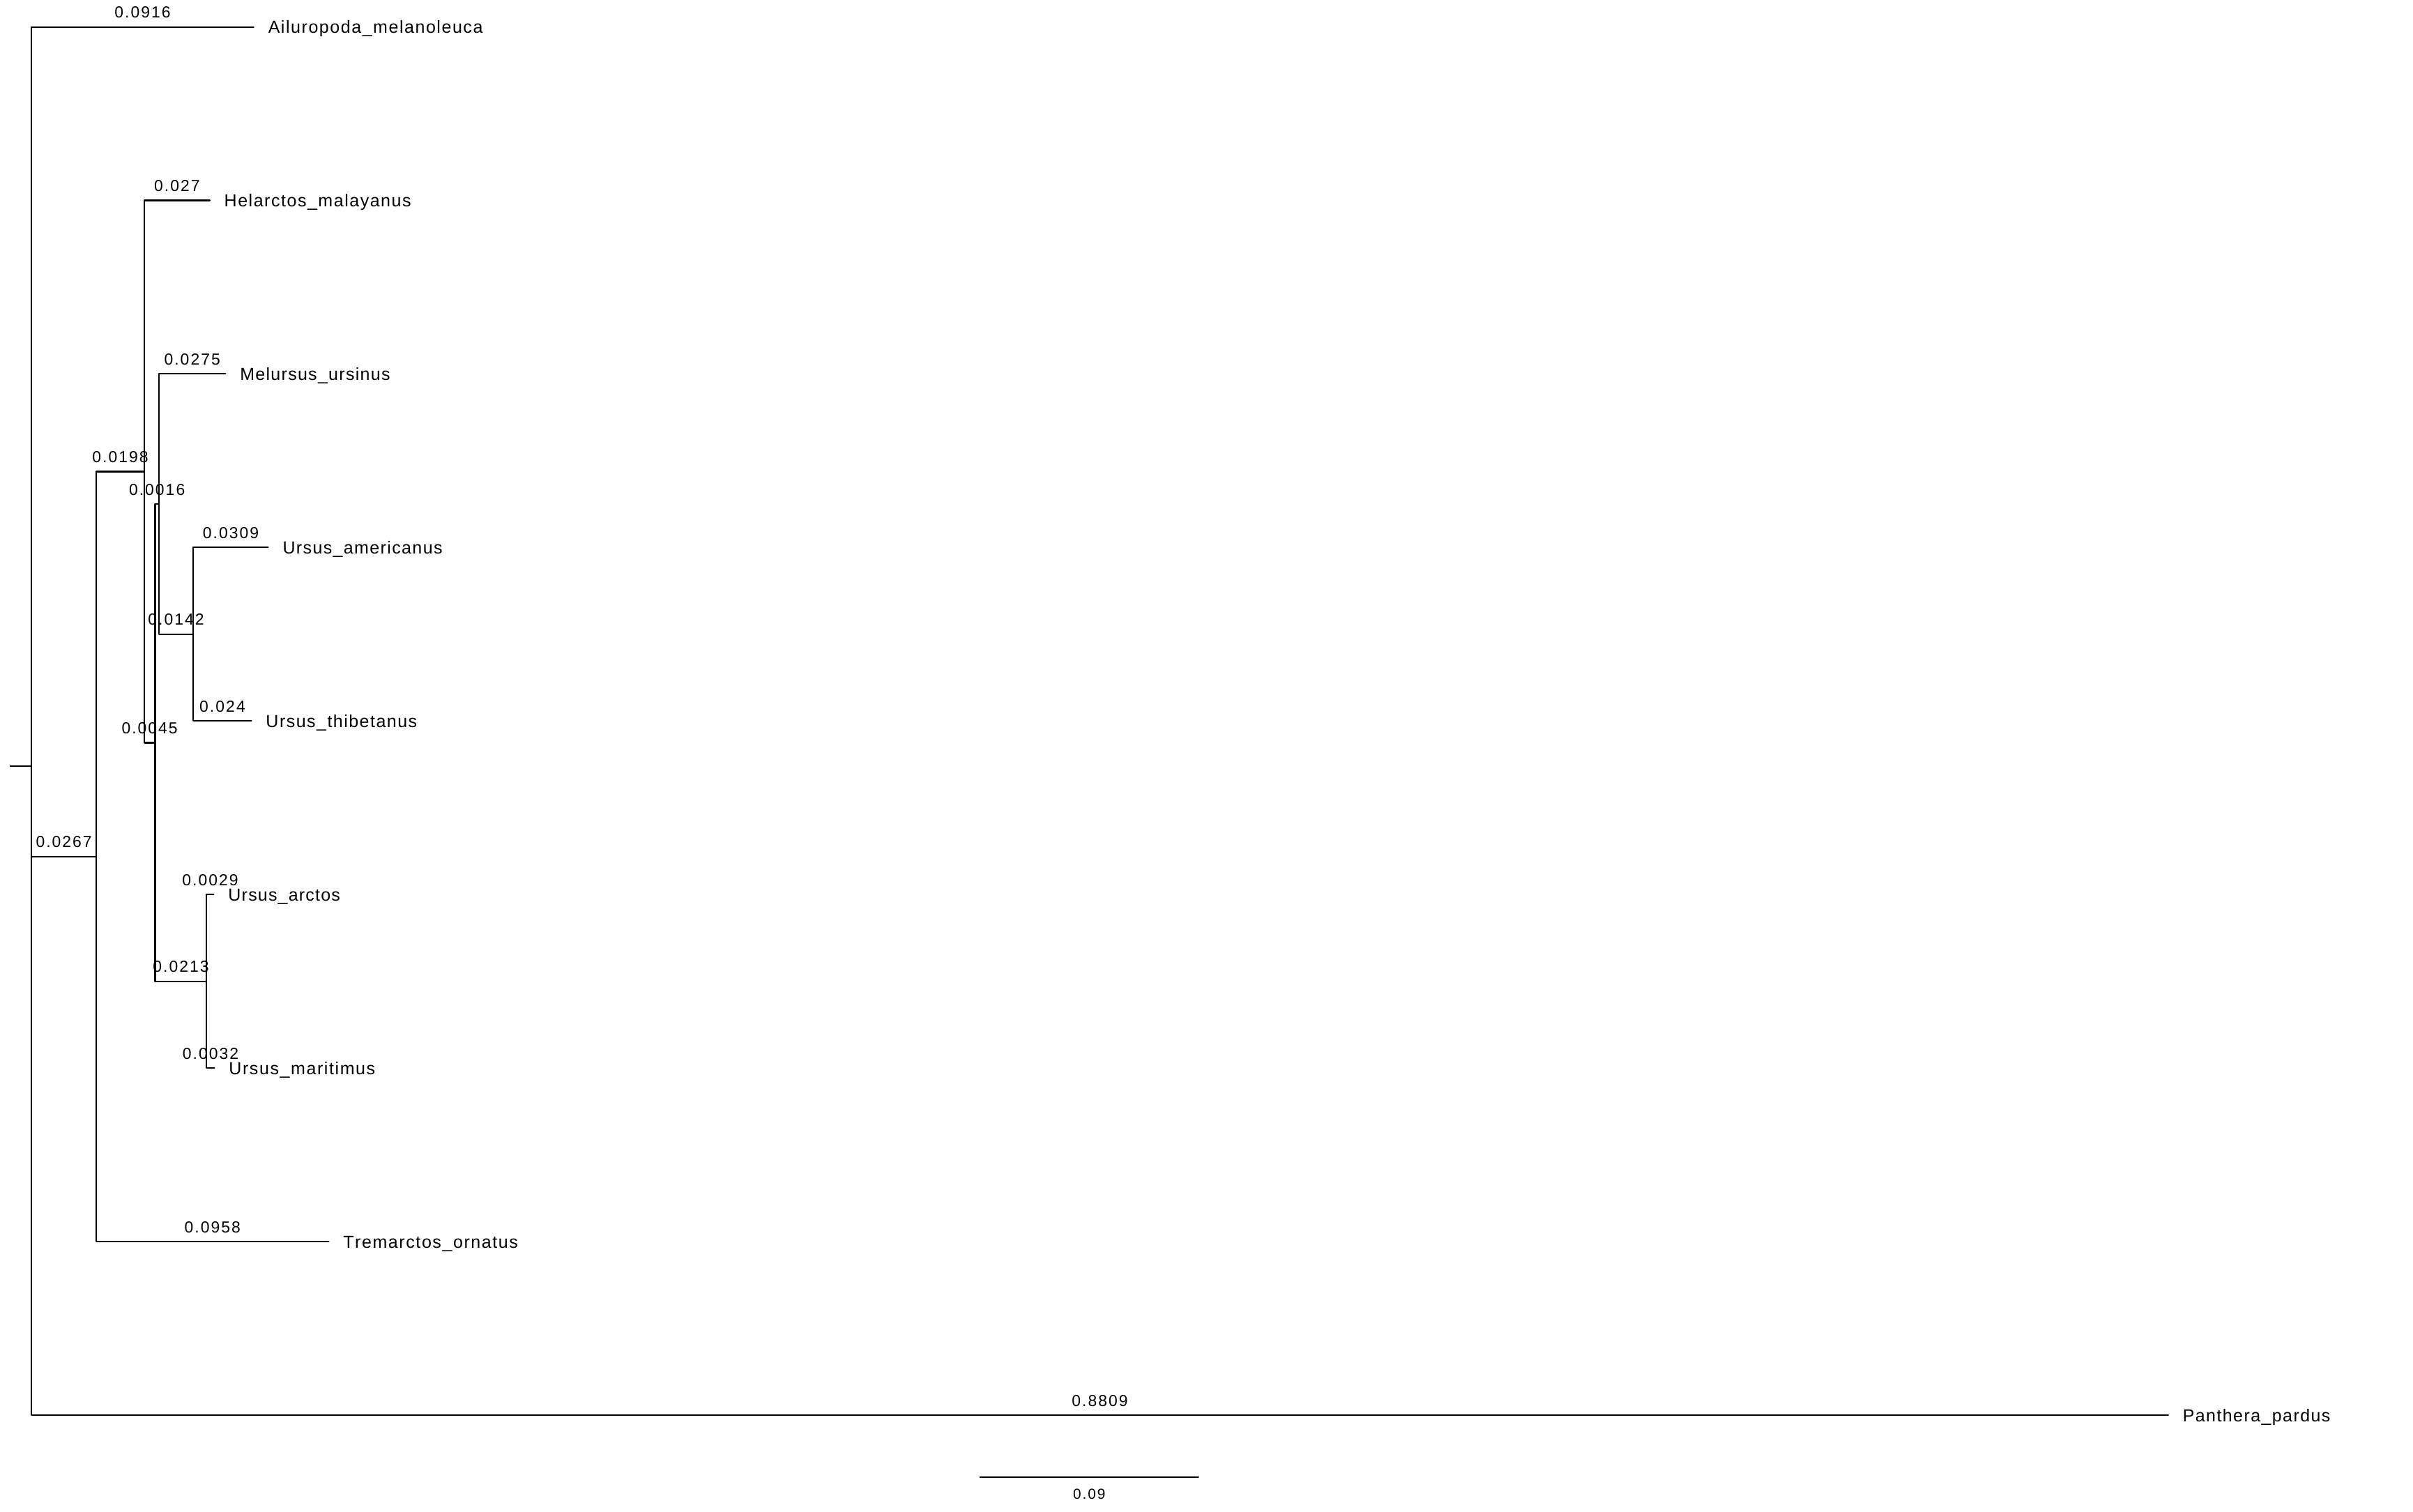

*Рисунок. Филогенетическое дерево семейства Ursidae, построенное методом максимального правдоподобия (IQ-TREE). Числа на ветвях показывают ожидаемое количество нуклеотидных замен на сайт (substitutions/site), а не время в миллионах лет.*

### Сравнение длин ветвей: байесовский метод (MrBayes)

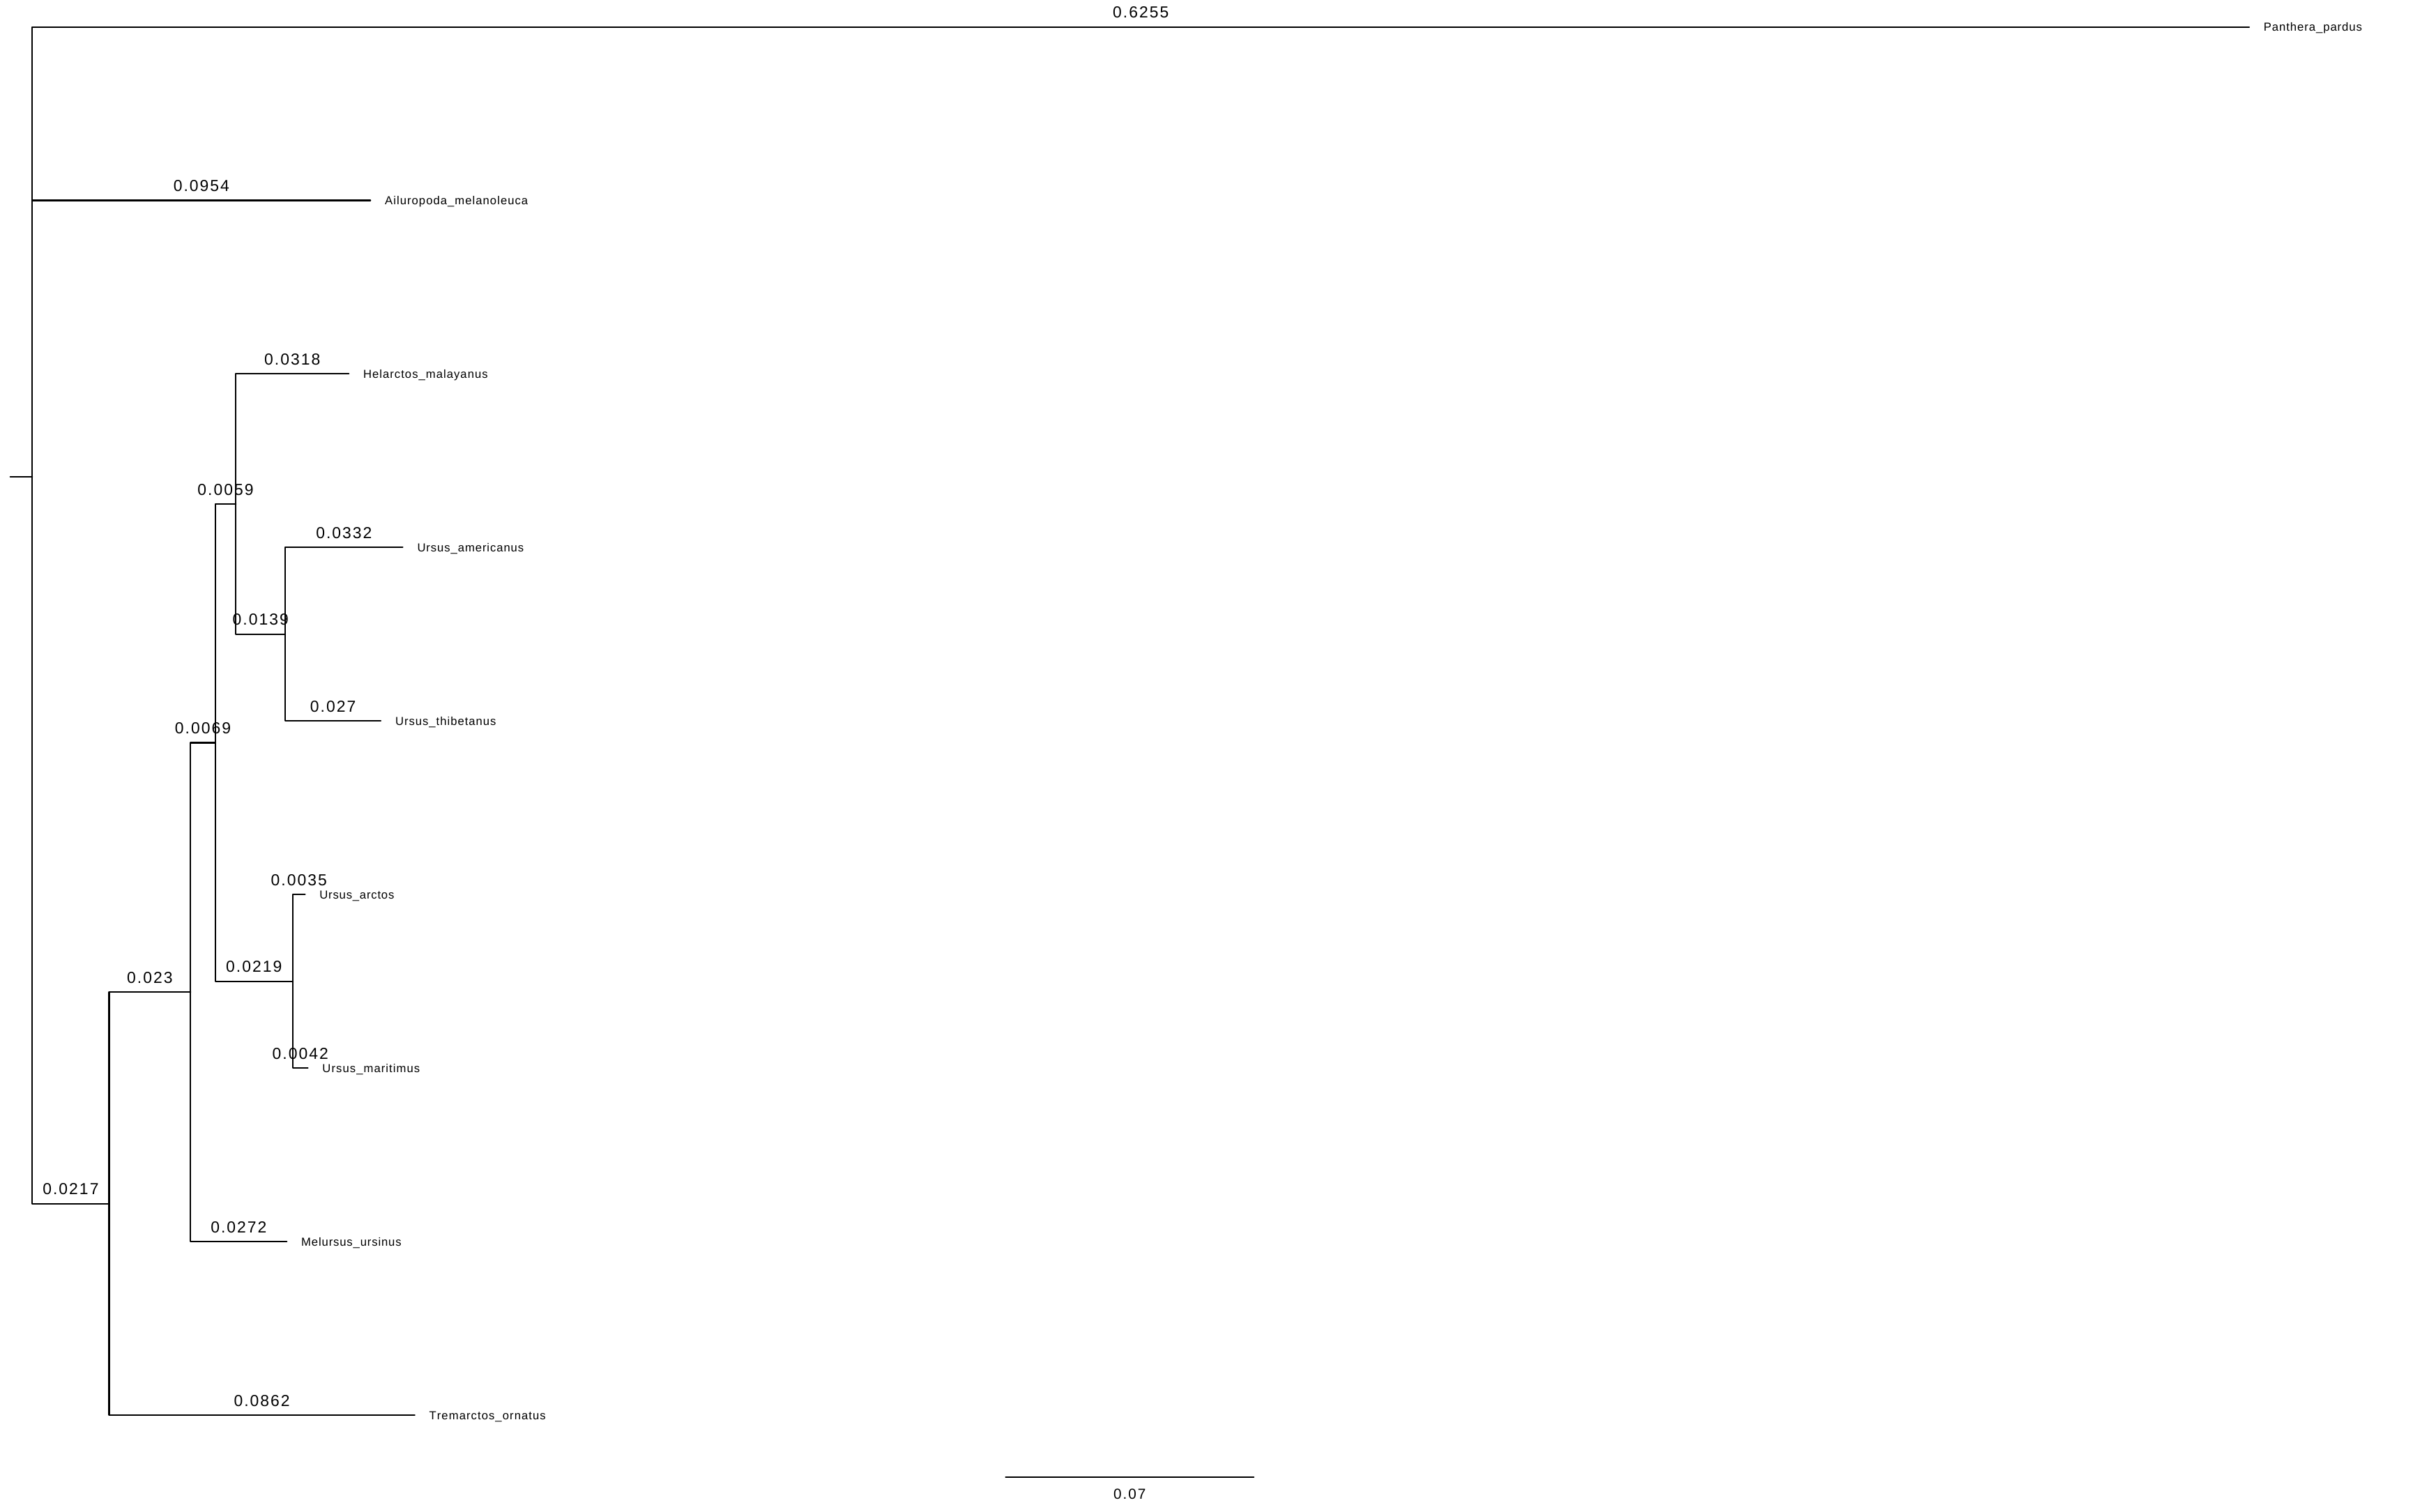

*Рисунок. Консенсусное филогенетическое дерево семейства Ursidae, полученное методом байесовского вывода (MrBayes). Числа на ветвях обозначают ожидаемое количество нуклеотидных замен на сайт (substitutions/site). Как и в анализе ML, длины ветвей отражают генетические изменения, а не абсолютное время эволюции.*

### Сравнение длин ветвей в анализах ML, MrBayes и BEAST2

В анализах максимального правдоподобия (ML, IQ-TREE) и байесовского вывода (BI, MrBayes) длины ветвей выражены в ожидаемом числе нуклеотидных замен на сайт (substitutions/site). Следовательно, они отражают степень генетических изменений, а не абсолютный возраст эволюционных событий.

Сравнение терминальных ветвей показывает небольшие различия между методами:

| Вид | ML (IQ-TREE) | BI (MrBayes) |
|---|---:|---:|
| *Ursus arctos* | 0.0029 | 0.0035 |
| *Ursus maritimus* | 0.0032 | 0.0042 |
| *Ursus americanus* | 0.0309 | 0.0332 |
| *Ursus thibetanus* | 0.0240 | 0.0270 |

Для рассмотренных видов оценки длин ветвей в MrBayes несколько выше, чем в IQ-TREE. При этом оба метода подтверждают близкое родство *Ursus arctos* и *Ursus maritimus*, а также *Ursus americanus* и *Ursus thibetanus*.

В отличие от этих анализов, в калиброванном дереве BEAST2 длины ветвей представлены во временной шкале. Оценённый возраст общего предка *Ursus arctos* и *Ursus maritimus* составляет около 11.47 млн лет, а возраст корня дерева — около 15.59 млн лет.

Сопоставление топологии деревьев и результатов анализа позволяет оценить согласованность филогенетических выводов, полученных разными методами.

### Сравнение результатов ML (IQ-TREE), MrBayes и BEAST2

**1. Топология и поддержка узлов**

Все три метода подтвердили близкое родство *Ursus arctos* и *Ursus maritimus*, а также *Ursus americanus* и *Ursus thibetanus*.

Поддержка этих клад составила:
- **ML (IQ-TREE):** 99,9/92 и 99/80 (SH-aLRT/UFBoot).
- **MrBayes:** 0,9999 и 0,9484 (PP).
- **BEAST2:** 1,00 и 0,99 (PP).

При этом обнаружены различия в топологии: в BEAST2 *Ailuropoda* и *Tremarctos* образуют кладу (PP = 1,00), отсутствующую в деревьях ML и MrBayes. Объединение *Melursus* с кладой *U. americanus + U. thibetanus* имеет слабую поддержку (PP = 0,42).

**2. Диагностика MCMC в BEAST2**

Анализ в Tracer показал низкие значения ESS для ряда параметров: posterior — 74, likelihood — 163, kappa — 38 (cytb) и 59 (irbp), gamma shape — 61 (cytb) и 45 (irbp), mutation rate — 27 (cytb) и 277 (irbp).

Большинство значений ESS ниже рекомендуемого порога 200.

**Вывод**

Основные клады *Ursus* подтверждаются всеми тремя методами, несмотря на различия в расположении отдельных таксонов.